# Weather and population data: preparation of the processed tables

**What this notebook does.** It builds the regional tables that the analysis notebooks use:

1. **Map of the grid nodes** (section *Map of the stations*): the ERA5 grid points used in the United States, Spain and the Netherlands.
2. **Yearly weather by region** (section *Data extraction and preparation*): averages the daily values of all grid nodes of each region and then summarises each year (mean temperature, total rain and rain hours, mean daylight, cloud cover and wind). The first cells show the steps one by one for one year; the last three cells build the full 2001–2021 tables for Spain, the United States and the Netherlands.
3. **Population by region and year** (section *Population Data*): U.S. Census Bureau estimates and Eurostat (table `demo_r_d2jan`).

**Inputs**
- `data/interim/weather_data/`: daily weather by grid node, 2001–2021 (Parquet, about 800 MB, not in GitHub). It is created with the scripts in `src/weather/` (see the README).
- Internet access: map boundaries (Census Bureau, Eurostat GISCO) and population data.

**Outputs** (in `data/processed/`)
- `spain_yearly.csv`, `usa_yearly.csv`, `NL_yearly.csv`: one row per region and year with the weather variables.
- `usa_population.csv`, `spain_population.csv`, `NL_population.csv`: one row per region and year with the population.

**How to run.** Open the notebook from the `notebooks/` folder and use *Run All*. All paths are relative to the repository (cell below).

In [ ]:
from pathlib import Path

# Repository root: the first folder, going up from this notebook, that contains "data/"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
RAW = ROOT / "data" / "raw"              # original downloads (not uploaded to GitHub)
INTERIM = ROOT / "data" / "interim"      # large intermediate files (not uploaded to GitHub)
PROCESSED = ROOT / "data" / "processed"  # clean tables used in the analysis

## Jupyter for Weatherinformation

Weather data

Source: ERA5 reanalysis, obtained from the Open-Meteo open-data repository.
Coverage: daily values from 2001-01-01 to 2021-12-31 for 18,558 grid nodes
(0.25° grid, about 25 km) located in the United States (50 states + DC),
Spain (19 NUTS-2 regions) and the Netherlands (12 provinces).

Variables (one value per node and day, days in UTC):
- temperature_2m_mean: mean air temperature at 2 m (°C)
- precipitation_hours: number of hours with precipitation (h)
- rain_sum: total rainfall, excluding snow (mm)
- daylight_duration: time between sunrise and sunset (s)

Format: Apache Parquet.
- daily/YYYY.parquet: one file per year (21 files, about 142 million rows,
  410 MB in total). Columns: node_id, date and the four variables.
- nodes.parquet: one row per node with node_id, latitude, longitude,
  country, region_code and region_name.
The two tables are linked by node_id. Data are stored per node; regional
averages are computed by grouping the nodes of each region.

The values were checked against the Open-Meteo API for a sample of nodes
and match it (differences below 0.05 °C for temperature, none for rainfall).

Citation Weather 
Zippenfenig, P. (2023). Open-Meteo.com Weather API [Computer software]. Zenodo. https://doi.org/10.5281/ZENODO.7970649

Hersbach, H., Bell, B., Berrisford, P., Biavati, G., Horányi, A., Muñoz Sabater, J., Nicolas, J., Peubey, C., Radu, R., Rozum, I., Schepers, D., Simmons, A., Soci, C., Dee, D., Thépaut, J-N. (2023). ERA5 hourly data on single levels from 1940 to present [Data set]. ECMWF. https://doi.org/10.24381/cds.adbb2d47

Muñoz Sabater, J. (2019). ERA5-Land hourly data from 2001 to present [Data set]. ECMWF. https://doi.org/10.24381/CDS.E2161BAC

Schimanke S., Ridal M., Le Moigne P., Berggren L., Undén P., Randriamampianina R., Andrea U., Bazile E., Bertelsen A., Brousseau P., Dahlgren P., Edvinsson L., El Said A., Glinton M., Hopsch S., Isaksson L., Mladek R., Olsson E., Verrelle A., Wang Z.Q. (2021). CERRA sub-daily regional reanalysis data for Europe on single levels from 1984 to present [Data set]. ECMWF. https://doi.org/10.24381/CDS.622A565A

# Map of the stations.

This map represents the nodes that were used to get a more acurrate average of, temperature, rain and Sun Light 

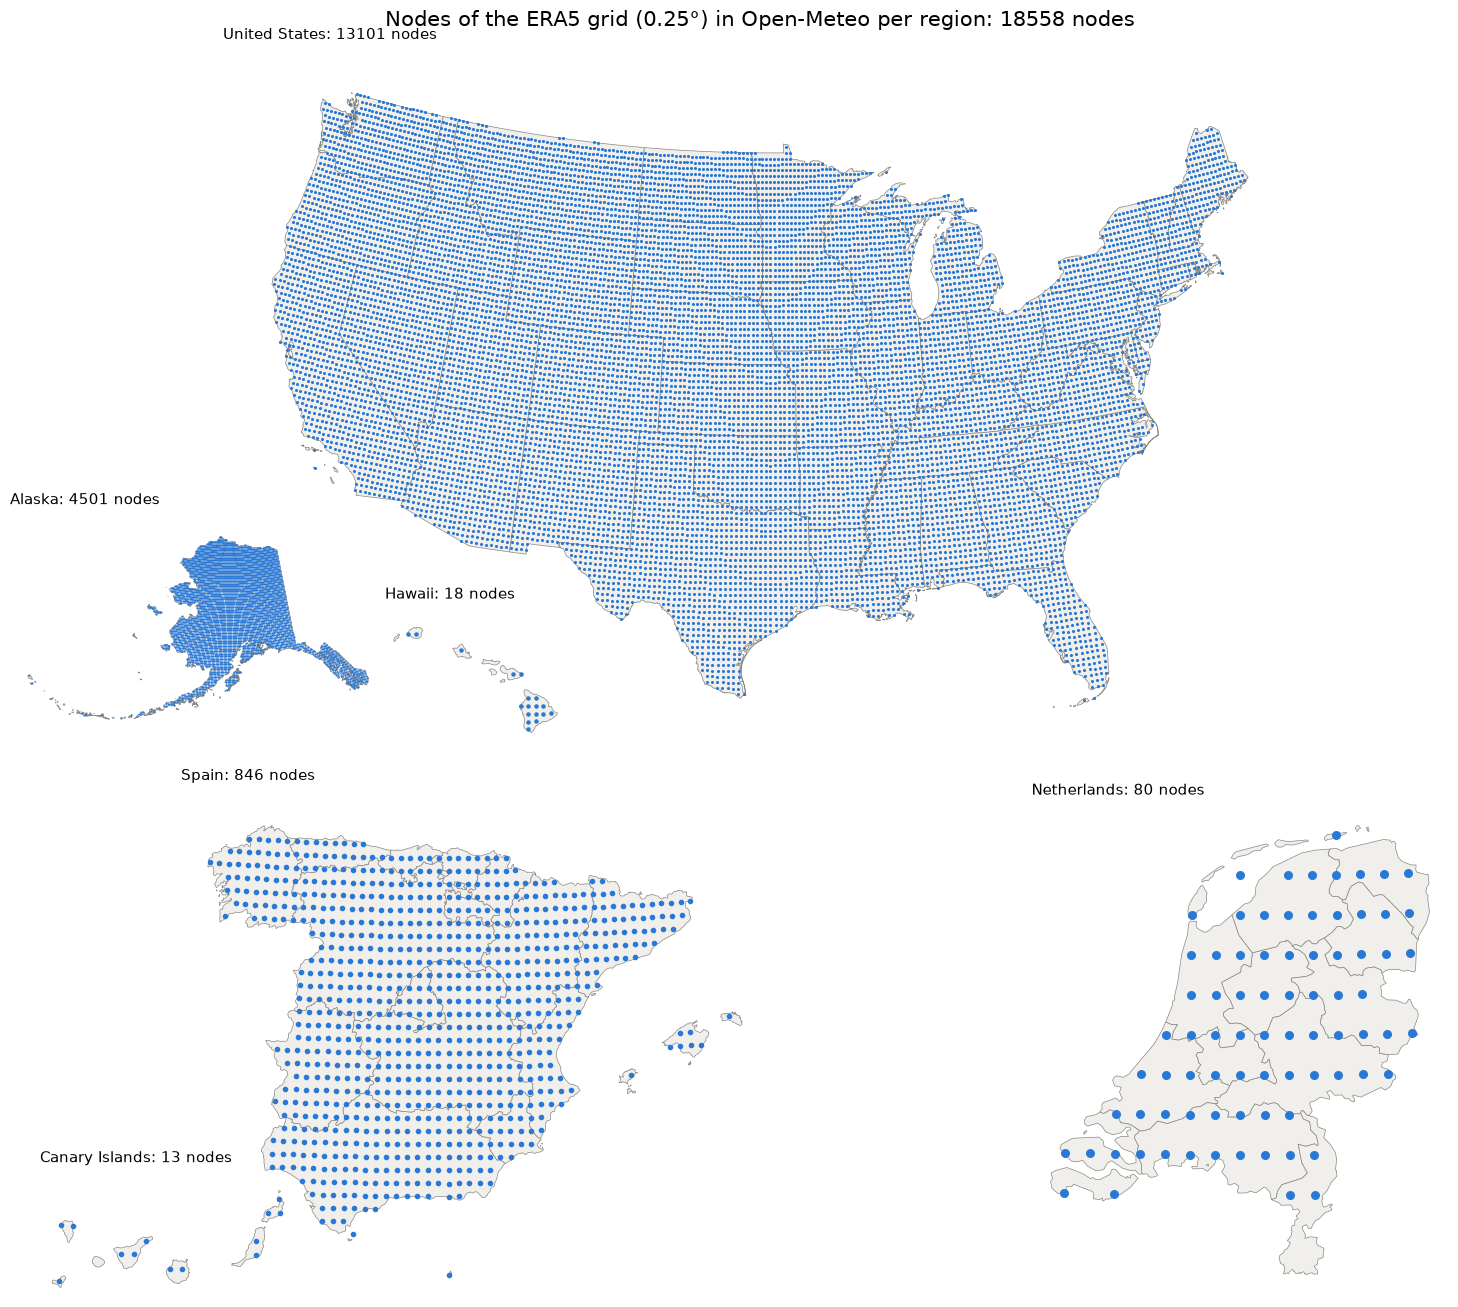

In [8]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Frontiers of all the states of the USA (Census Bureau)
url_us = "https://www2.census.gov/geo/tiger/GENZ2018/shp/cb_2018_us_state_5m.zip"
states = gpd.read_file(url_us).to_crs("EPSG:4326")
states = states[states["STATEFP"].astype(int) <= 56]
states = states.assign(code="US-" + states["STUSPS"], name=states["NAME"])[["code", "name", "geometry"]]

# Frontiers of the regions of Spain (autonomous communities) and the Netherlands (provinces): NUTS-2, Eurostat
url_eu = "https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_03M_2021_4326_LEVL_2.geojson"
nuts = gpd.read_file(url_eu).to_crs("EPSG:4326")
nuts = nuts[nuts["CNTR_CODE"].isin(["ES", "NL"])]
nuts = nuts.assign(code=nuts["NUTS_ID"], name=nuts["NAME_LATN"])[["code", "name", "geometry"]]

regions = pd.concat([states, nuts], ignore_index=True)

# Candidate nodes of the ERA5 grid (multiples of 0.25 degrees) between 18 and 72 degrees north
lon, lat = np.meshgrid(np.arange(-180, 180, 0.25), np.arange(18, 72, 0.25))
nodes = gpd.GeoDataFrame(geometry=gpd.points_from_xy(lon.ravel(), lat.ravel()), crs="EPSG:4326")

# Selecting the nodes that are within the regions
pts = gpd.sjoin(nodes, regions, predicate="within").drop(columns="index_right")

# Regions too small to contain a node (DC, Ceuta, Melilla): use the nearest node
small = regions[~regions["code"].isin(pts["code"])]
center = small.geometry.representative_point()
nearest = gpd.GeoDataFrame(
    small[["code", "name"]],
    geometry=gpd.points_from_xy((center.x / 0.25).round() * 0.25, (center.y / 0.25).round() * 0.25),
    crs="EPSG:4326",
)
pts = pd.concat([pts, nearest], ignore_index=True)
total = len(set(zip(pts.geometry.x, pts.geometry.y)))  # a node shared by two regions counts once

# Map: the 48 states with Alaska and Hawaii, Spain with the Canary Islands, and the Netherlands
code = regions["code"]
paneles = [  # (title, regions, projection, position in the figure, point size)
    ("United States",  code.str.startswith("US") & ~code.isin(["US-AK", "US-HI"]), "EPSG:5070", [0.00, 0.43, 1.00, 0.52], 1.5),
    ("Alaska",         code == "US-AK",                         "EPSG:3338",   [0.00, 0.43, 0.25, 0.17], 0.3),
    ("Hawaii",         code == "US-HI",                         "ESRI:102007", [0.25, 0.43, 0.12, 0.09], 5),
    ("Spain",          code.str.startswith("ES") & (code != "ES70"), "EPSG:25830", [0.02, 0.00, 0.58, 0.38], 9),
    ("Canary Islands", code == "ES70",                          "EPSG:32628",  [0.02, 0.00, 0.17, 0.09], 9),
    ("Netherlands",    code.str.startswith("NL"),               "EPSG:28992",  [0.66, 0.00, 0.32, 0.38], 30),
]
fig = plt.figure(figsize=(15, 13))
for title, mask, crs, pos, size in paneles:
    ax = fig.add_axes(pos)
    sel = regions[mask]
    p = pts[pts["code"].isin(sel["code"])]
    sel.to_crs(crs).plot(ax=ax, color="#f0efec", edgecolor="#898781", linewidth=0.5)
    p.to_crs(crs).plot(ax=ax, color="#2a78d6", markersize=size)
    ax.set_axis_off()
    ax.set_title(f"{title}: {len(p)} nodes", fontsize=11, loc="left")
fig.suptitle(f"Nodes of the ERA5 grid (0.25°) in Open-Meteo per region: {total} nodes", fontsize=15, y=0.99)
plt.show()

Data extraction and preparation

In [9]:
import pandas as pd

folder = INTERIM / "weather_data"   # daily weather by grid node (made with src/weather/)
variables = ["temperature_2m_mean", "precipitation_hours", "rain_sum", "daylight_duration"]

In [10]:
import pandas as pd
#Import the complete Data Set 
carpeta = INTERIM / "weather_data"

nodes = pd.read_parquet(f"{carpeta}/nodes.parquet")
nodes.head()

,node_id,latitude,longitude,country,region_code,region_name,assignment,iy,ix
0,761005,42.0,-8.75,ES,ES11,Galicia,inside,528,685
1,761008,42.0,-8.00,ES,ES11,Galicia,inside,528,688
2,761009,42.0,-7.75,ES,ES11,Galicia,inside,528,689
3,761010,42.0,-7.50,ES,ES11,Galicia,inside,528,690
4,761011,42.0,-7.25,ES,ES11,Galicia,inside,528,691


In [11]:
#Data preparation for Spain
spain = nodes[nodes["country"] == "ES"]
print(len(spain), "nodos en", spain["region_code"].nunique(), "regiones")

17620 nodos en 51 regiones


In [ ]:
ids = spain["node_id"].tolist() #Ids of spain

d = pd.read_parquet(f"{carpeta}/daily/2021.parquet", filters=[("node_id", "in", ids)])
print(len(d), "filas")
d.head()

313535 filas


,node_id,date,temperature_2m_mean,precipitation_hours,rain_sum,daylight_duration
0,678888,2021-01-01,18.200001,0,0.0,37525.871094
1,678888,2021-01-02,17.820000,0,0.0,37552.660156
2,678888,2021-01-03,18.160000,13,5.2,37581.519531
3,678888,2021-01-04,19.709999,7,2.2,37612.441406
4,678888,2021-01-05,19.950001,0,0.0,37645.371094


In [ ]:
d = d.merge(spain[["node_id", "region_code", "region_name"]], on="node_id")
print(len(d), "filas")
d.head()

313535 filas


,node_id,date,temperature_2m_mean,precipitation_hours,rain_sum,daylight_duration,region_code,region_name
0,678888,2021-01-01,18.200001,0,0.0,37525.871094,ES70,Canarias
1,678888,2021-01-02,17.820000,0,0.0,37552.660156,ES70,Canarias
2,678888,2021-01-03,18.160000,13,5.2,37581.519531,ES70,Canarias
3,678888,2021-01-04,19.709999,7,2.2,37612.441406,ES70,Canarias
4,678888,2021-01-05,19.950001,0,0.0,37645.371094,ES70,Canarias


In [ ]:
variables = ["temperature_2m_mean", "precipitation_hours", "rain_sum", "daylight_duration"]

diario = d.groupby(["region_code", "region_name", "date"])[variables].mean().reset_index()
print(len(diario), "filas")
diario.head()

6935 filas


,region_code,region_name,date,temperature_2m_mean,precipitation_hours,rain_sum,daylight_duration
0,ES11,Galicia,2021-01-01,3.1118,13.96,4.592,32781.546875
1,ES11,Galicia,2021-01-02,2.9094,2.88,0.568,32831.320312
2,ES11,Galicia,2021-01-03,3.3002,14.14,3.706,32884.921875
3,ES11,Galicia,2021-01-04,1.9322,4.06,0.772,32942.304688
4,ES11,Galicia,2021-01-05,1.2304,1.98,0.366,33003.390625


In [ ]:
diario[diario["region_code"] == "ES30"].head(3)

,region_code,region_name,date,temperature_2m_mean,precipitation_hours,rain_sum,daylight_duration
2555,ES30,Comunidad de Madrid,2021-01-01,2.068000,5.400000,0.533333,33624.523438
2556,ES30,Comunidad de Madrid,2021-01-02,-0.074000,0.133333,0.000000,33670.011719
2557,ES30,Comunidad de Madrid,2021-01-03,0.299333,0.333333,0.000000,33719.007812


In [ ]:
diario["year"] = diario["date"].dt.year

anual = diario.groupby(["region_code", "region_name", "year"]).agg(
    temperature_2m_mean=("temperature_2m_mean", "mean"),
    precipitation_hours=("precipitation_hours", "sum"),
    rain_sum=("rain_sum", "sum"),
    daylight_duration=("daylight_duration", "mean"),
).reset_index()
print(len(anual), "filas")
anual

19 filas


,region_code,region_name,year,temperature_2m_mean,precipitation_hours,rain_sum,daylight_duration
0,ES11,Galicia,2021,12.498262,1825.160000,1129.221924,43979.708818
1,ES12,Principado de Asturias,2021,11.539129,2219.900000,1257.114990,43990.299706
2,ES13,Cantabria,2021,11.601930,2237.142857,1202.742798,43987.542150
3,ES21,País Vasco,2021,12.503425,1932.230769,1147.515381,43984.950952
4,ES22,Comunidad Foral de Navarra,2021,12.603703,1418.500000,821.234985,43978.295901
5,ES23,La Rioja,2021,11.521699,1412.250000,678.825012,43971.144071
6,ES24,Aragón,2021,13.217405,950.888889,513.234558,43957.578071
7,ES30,Comunidad de Madrid,2021,13.678079,909.866667,452.146667,43941.303874
8,ES41,Castilla y León,2021,11.667688,1184.927711,586.922363,43962.396072
9,ES42,Castilla-La Mancha,2021,14.554444,859.044776,473.049255,43926.423063


In [3]:
# Nodes of Spain and the region each one belongs to
variables = ["temperature_2m_mean", "precipitation_hours", "rain_sum", "daylight_duration",
             "cloud_cover_mean", "wind_speed_100m_mean", "sunshine_duration"]
nodes = pd.read_parquet(f"{folder}/nodes.parquet")
spain = nodes[nodes["country"] == "ES"]
ids = spain["node_id"].tolist()

tables = []
for year in range(2001, 2022):
    # Daily data of this year, only for the Spanish nodes
    d = pd.read_parquet(f"{folder}/daily/{year}.parquet", filters=[("node_id", "in", ids)])

    # Add the region of each node
    d = d.merge(spain[["node_id", "region_code", "region_name"]], on="node_id")

    # Average the nodes of each region, day by day
    daily = d.groupby(["region_code", "region_name", "date"])[variables].mean().reset_index()

    # One row per region: mean for temperature and daylight, yearly total for rain
    daily["year"] = year
    yearly = daily.groupby(["region_code", "region_name", "year"]).agg(
        temperature_2m_mean=("temperature_2m_mean", "mean"),
        precipitation_hours=("precipitation_hours", "sum"),
        rain_sum=("rain_sum", "sum"),
        daylight_duration=("daylight_duration", "mean"),
        cloud_cover_mean=("cloud_cover_mean", "mean"),
        wind_speed_100m_mean=("wind_speed_100m_mean", "mean"),
        sunshine_duration=("sunshine_duration", lambda s: s.sum() / 3600),   # hours of sun in the year
    ).reset_index()
    tables.append(yearly)

# Join the 21 years: one row per region and year
spain_yearly = pd.concat(tables, ignore_index=True)
spain_yearly[variables] = spain_yearly[variables].astype(float).round(2)
print(len(spain_yearly), "rows")
spain_yearly
spain_yearly.to_csv(PROCESSED / 'spain_yearly.csv', index=False)

399 rows


In [10]:
import pandas as pd

folder = INTERIM / "weather_data"
variables = ["temperature_2m_mean", "precipitation_hours", "rain_sum", "daylight_duration",
             "cloud_cover_mean", "wind_speed_100m_mean", "sunshine_duration"]

# Nodes of USA and the region each one belongs to
nodes = pd.read_parquet(f"{folder}/nodes.parquet")
USA = nodes[nodes["country"] == "US"]
ids = USA["node_id"].tolist()

tables = []
for year in range(2001, 2022):
    # Daily data of this year, only for the Spanish nodes
    d = pd.read_parquet(f"{folder}/daily/{year}.parquet", filters=[("node_id", "in", ids)])

    # Add the region of each node
    d = d.merge(USA[["node_id", "region_code", "region_name"]], on="node_id")

    # Average the nodes of each region, day by day
    daily = d.groupby(["region_code", "region_name", "date"])[variables].mean().reset_index()

    # One row per region: mean for temperature and daylight, yearly total for rain
    daily["year"] = year
    yearly = daily.groupby(["region_code", "region_name", "year"]).agg(
        temperature_2m_mean=("temperature_2m_mean", "mean"),
        precipitation_hours=("precipitation_hours", "sum"),
        rain_sum=("rain_sum", "sum"),
        daylight_duration=("daylight_duration", "mean"),
        cloud_cover_mean=("cloud_cover_mean", "mean"),
        wind_speed_100m_mean=("wind_speed_100m_mean", "mean"),
        sunshine_duration=("sunshine_duration", lambda s: s.sum() / 3600),   # hours of sun in the year
    ).reset_index()
    tables.append(yearly)

# Join the 21 years: one row per region and year
usa_yearly = pd.concat(tables, ignore_index=True)
usa_yearly[variables] = usa_yearly[variables].astype(float).round(2)
print(len(usa_yearly), "rows")
usa_yearly
usa_yearly.to_csv(PROCESSED / 'usa_yearly.csv', index=False)

1071 rows


In [11]:
# Nodes of USA and the region each one belongs to

nodes = pd.read_parquet(f"{folder}/nodes.parquet")
NL = nodes[nodes["country"] == "NL"]
ids = NL["node_id"].tolist()

tables = []
for year in range(2001, 2022):
    # Daily data of this year, only for the Spanish nodes
    d = pd.read_parquet(f"{folder}/daily/{year}.parquet", filters=[("node_id", "in", ids)])

    # Add the region of each node
    d = d.merge(NL[["node_id", "region_code", "region_name"]], on="node_id")

    # Average the nodes of each region, day by day
    daily = d.groupby(["region_code", "region_name", "date"])[variables].mean().reset_index()

    # One row per region: mean for temperature and daylight, yearly total for rain
    daily["year"] = year
    yearly = daily.groupby(["region_code", "region_name", "year"]).agg(
        temperature_2m_mean=("temperature_2m_mean", "mean"),
        precipitation_hours=("precipitation_hours", "sum"),
        rain_sum=("rain_sum", "sum"),
        daylight_duration=("daylight_duration", "mean"),
        cloud_cover_mean=("cloud_cover_mean", "mean"),
        wind_speed_100m_mean=("wind_speed_100m_mean", "mean"),
        sunshine_duration=("sunshine_duration", lambda s: s.sum() / 3600),   # hours of sun in the year
    ).reset_index()
    tables.append(yearly)

# Join the 21 years: one row per region and year
NL_yearly = pd.concat(tables, ignore_index=True)
NL_yearly[variables] = NL_yearly[variables].astype(float).round(2)
print(len(NL_yearly), "rows")
NL_yearly
NL_yearly.to_csv(PROCESSED / 'NL_yearly.csv', index=False)

252 rows


## Population Data 

In [1]:
import pandas as pd

base = "https://www2.census.gov/programs-surveys/popest/datasets"

# 2001-2009: intercensal estimates 2000-2010 (the rows with SEX, ORIGIN, RACE and AGEGRP = 0 are the totals)
a = pd.read_csv(f"{base}/2000-2010/intercensal/state/st-est00int-alldata.csv", encoding="latin-1")
a = a[(a["SEX"] == 0) & (a["ORIGIN"] == 0) & (a["RACE"] == 0) & (a["AGEGRP"] == 0)]
a = a.melt(id_vars="STATE", value_vars=[f"POPESTIMATE{y}" for y in range(2001, 2010)], var_name="year", value_name="population")

# 2010-2019: intercensal estimates 2010-2020 (sum of the 6 race groups and all ages)
b = pd.read_csv(f"{base}/2010-2020/intercensal/state/asrh/sc-est2020int-alldata6.csv", encoding="latin-1")
b = b[(b["SEX"] == 0) & (b["ORIGIN"] == 0)]
b = b.groupby("STATE")[[f"POPESTIMATE{y}" for y in range(2010, 2020)]].sum().reset_index()
b = b.melt(id_vars="STATE", var_name="year", value_name="population")

# 2020-2021: postcensal estimates, Vintage 2025
c = pd.read_csv(f"{base}/2020-2025/state/totals/NST-EST2025-ALLDATA.csv", encoding="latin-1")
c = c.melt(id_vars="STATE", value_vars=["POPESTIMATE2020", "POPESTIMATE2021"], var_name="year", value_name="population")

# Join the three periods and keep the 50 states + DC (codes 1 to 56)
pop = pd.concat([a, b, c], ignore_index=True)
pop = pop[(pop["STATE"] >= 1) & (pop["STATE"] <= 56)]
pop["year"] = pop["year"].str[-4:].astype(int)

# Add the state code (US-CA, US-TX...) and name
states = pd.read_csv("https://www2.census.gov/geo/docs/reference/state.txt", sep="|")
pop = pop.merge(states, on="STATE")
pop["region_code"] = "US-" + pop["STUSAB"]
usa_population = (pop.rename(columns={"STATE_NAME": "region_name"})
                     [["region_code", "region_name", "year", "population"]]
                     .sort_values(["region_code", "year"]).reset_index(drop=True))
print(len(usa_population), "rows")
usa_population.to_csv(PROCESSED / "usa_population.csv", index=False)
usa_population

1071 rows


,region_code,region_name,year,population
0,US-AK,Alaska,2001,633714
1,US-AK,Alaska,2002,642337
2,US-AK,Alaska,2003,648414
3,US-AK,Alaska,2004,659286
4,US-AK,Alaska,2005,666946
...,...,...,...,...
1066,US-WY,Wyoming,2017,576240
1067,US-WY,Wyoming,2018,574783
1068,US-WY,Wyoming,2019,575327
1069,US-WY,Wyoming,2020,577669


In [2]:
import pandas as pd

# Population on 1 January by NUTS-2 region, 2001-2021 (Eurostat, table demo_r_d2jan)
url = ("https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/data/demo_r_d2jan/A.NR.T.TOTAL."
       "?format=SDMX-CSV&startPeriod=2001&endPeriod=2021")
pop = pd.read_csv(url)

# Keep the regions of Spain (ES + 2 digits: the 17 autonomous communities, Ceuta and Melilla)
pop = pop[pop["geo"].str.fullmatch(r"ES\d\d")]

# Add the region name
names = pd.read_csv("https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/codelist/ESTAT/GEO/latest?format=TSV&lang=en",
                    sep="\t", header=None, names=["geo", "region_name"])
pop = pop.merge(names, on="geo")

spain_population = (pop.rename(columns={"geo": "region_code", "TIME_PERIOD": "year", "OBS_VALUE": "population"})
                       [["region_code", "region_name", "year", "population"]]
                       .sort_values(["region_code", "year"]).reset_index(drop=True))
print(len(spain_population), "rows")
spain_population.to_csv(PROCESSED / "spain_population.csv", index=False)
spain_population

399 rows


,region_code,region_name,year,population
0,ES11,Galicia,2001,2698025
1,ES11,Galicia,2002,2696809
2,ES11,Galicia,2003,2705159
3,ES11,Galicia,2004,2711586
4,ES11,Galicia,2005,2720689
...,...,...,...,...
394,ES70,Canarias,2017,2115233
395,ES70,Canarias,2018,2131581
396,ES70,Canarias,2019,2153316
397,ES70,Canarias,2020,2176240


In [3]:
import pandas as pd

# Population on 1 January by NUTS-2 region, 2001-2021 (Eurostat, table demo_r_d2jan)
url = ("https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/data/demo_r_d2jan/A.NR.T.TOTAL."
       "?format=SDMX-CSV&startPeriod=2001&endPeriod=2021")
pop = pd.read_csv(url)

# Keep the 12 provinces of the Netherlands. NL35 and NL36 are new codes for Utrecht and
# Zuid-Holland that only start in 2014; the weather data uses NL31 and NL33
pop = pop[pop["geo"].str.fullmatch(r"NL\d\d") & ~pop["geo"].isin(["NL35", "NL36"])]

# Add the region name
names = pd.read_csv("https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/codelist/ESTAT/GEO/latest?format=TSV&lang=en",
                    sep="\t", header=None, names=["geo", "region_name"])
names["region_name"] = names["region_name"].str.replace(r" \(NUTS \d{4}\)", "", regex=True)
pop = pop.merge(names, on="geo")

NL_population = (pop.rename(columns={"geo": "region_code", "TIME_PERIOD": "year", "OBS_VALUE": "population"})
                    [["region_code", "region_name", "year", "population"]]
                    .sort_values(["region_code", "year"]).reset_index(drop=True))
print(len(NL_population), "rows")
NL_population.to_csv(PROCESSED / "NL_population.csv", index=False)
NL_population

252 rows


,region_code,region_name,year,population
0,NL11,Groningen,2001,566489
1,NL11,Groningen,2002,570480
2,NL11,Groningen,2003,572997
3,NL11,Groningen,2004,574384
4,NL11,Groningen,2005,575072
...,...,...,...,...
247,NL42,Limburg (NL),2017,1117546
248,NL42,Limburg (NL),2018,1117198
249,NL42,Limburg (NL),2019,1116137
250,NL42,Limburg (NL),2020,1117201
